<center><p float="center">
  <img src="https://vectorseek.com/wp-content/uploads/2023/08/Massachusetts-Institute-of-Technology-MIT-Logo-Vector.svg-.png" width="360"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="200"/>
</p></center>

<center><font size=10>AI and Data Science</font></center>
<center><font size=6>Week 4: AI-Assisted Exploratory Analysis - MLS</font></center>

<center><p float="center">
  <img src="https://images.pexels.com/photos/37730212/pexels-photo-37730212.jpeg" alt="Virtual Machines" width="640"/>
</p></center>
<center><font size=5>Cloud VM Segmentation</font></center>

## Problem Statement

### Business Context

Atlas Financial Group, a regional bank, runs its on-demand VM fleet across two regional cloud providers. As a regulated financial institution operating on margin-sensitive retail and commercial banking lines, every cost centre is scrutinised by both the CFO and external auditors, and cloud compute has become one of the fastest-growing line items on the books. A modernisation programme over the last three years lifted most workloads from on-premises data centres into the cloud, but the team is still operating with lift-and-shift sizing decisions made under "better safe than sorry" assumptions.

An internal audit found that roughly 31% of VMs are averaging under 15% CPU utilization, fully billable compute that is largely doing nothing, translating to an estimated \$8M of annual waste against a $52M cloud bill. The FinOps team's target is to bring this under 12% within two billing cycles.

The waste is easy to detect. A simple average CPU filter surfaces it in minutes. The hard part is that average CPU alone cannot tell you what action to take. A VM at 8% CPU could be a forgotten zombie that should be killed, an over-provisioned server that should be downsized, or a bursty daytime API that spikes to 80% at noon and would break if touched. One filter, three different actions, and getting it wrong means a 2 am incident call.
Today the Cloud Platform team investigates each VM individually and chases application owners for sign-off. Owners have no incentive to shrink their own resources. The process stalls, waste compounds, and the team cannot keep up.

What Atlas needs is to turn thousands of individual negotiations into a handful of defensible group-level decisions by classifying every VM into a behavioural archetype and attaching one sizing action per archetype.


### Objective

The objective is to group Atlas's on-demand VM fleet into a small number of distinct behavioural archetypes based on actual utilization and workload patterns, providing the FinOps team with an explainable and defensible view of how each VM operates, not just what it costs. The resulting archetypes will serve as the foundation for a standardised sizing and optimisation policy, enabling CFO and engineering leadership to make consistent, fleet-level decisions without negotiating thousands of individual VMs.


**Scope of this prototype:**

This prototype works with a 2-day observation window across 1,500 VMs (~765,000 readings) and uses CPU and memory utilization features. It is sufficient to validate the methodology and prove that distinct archetypes emerge from behavioural data alone.

A production deployment will require two expansions:
- **More data** - at least 30 days of telemetry across the full ~4,500 VM fleet to capture weekly cycles, end-of-month batch jobs, and seasonal patterns that a short window cannot surface.

- **More features** - disk I/O and network throughput alongside CPU and memory, because a VM can look idle on CPU while being bottlenecked on another resource, and downsizing it would trigger a workload failure.

The pipeline, feature engineering approach, and clustering technique stay the same; only the data volume and feature breadth scale up.

### Data Dictionary

The dataset is provided as **four related tables** that combine on the **`vm_id`** key (and the bucket keys for the size lookup) to give a unified view of each Virtual Machine (VM).

#### 1. VM Information (`vm_info.csv`)
One record per VM with metadata about its lifecycle and provisioned configuration.

| Attribute           | Description                                                                               |
| ------------------- | ----------------------------------------------------------------------------------------- |
| `vm_id`             | Unique identifier for the VM.                                                             |
| `subscription_id`   | The subscription the VM belongs to.                                                       |
| `deployment_id`     | The deployment the VM was provisioned under.                                              |
| `vm_created_ts`     | VM creation timestamp (Unix epoch seconds).                                               |
| `vm_deleted_ts`     | VM deletion timestamp (Unix epoch seconds). Blank values indicate the VM is still active. |
| `vm_category`       | Workload type of the VM (`Interactive` or `Delay-Insensitive`).                           |
| `core_count_bucket` | Bucket representing the provisioned vCPU allocation.                                      |
| `memory_bucket`     | Bucket representing the provisioned memory allocation.                                    |

#### 2. VM Utilization Time Series (`vm_utilization_timeseries.csv`)
Resource utilization metrics collected every 5 minutes for each VM.

| Attribute         | Description                                                        |
| ----------------- | ------------------------------------------------------------------ |
| `vm_id`           | Unique identifier for the VM.                                      |
| `timestamp`       | Start time of the 5-minute monitoring window (Unix epoch seconds, UTC). |
| `min_cpu_5min`    | Minimum CPU utilization (%) observed during the window.            |
| `max_cpu_5min`    | Maximum CPU utilization (%) observed during the window.            |
| `avg_cpu_5min`    | Average CPU utilization (%) during the window.                     |
| `min_memory_5min` | Minimum memory utilization (%) observed during the window.         |
| `max_memory_5min` | Maximum memory utilization (%) observed during the window.         |
| `avg_memory_5min` | Average memory utilization (%) during the window.                  |


#### 3. CPU Type Definitions (`cpu_type_definitions.csv`)

Defines the CPU configuration buckets used to categorize VMs based on their provisioned vCPU capacity.

| Attribute | Description |
|-----------|-------------|
| `core_count_bucket` | Unique identifier for the CPU configuration bucket. |
| `bucket_category` | Descriptive label assigned to the CPU capacity range. |
| `min_value` | Lower bound of the vCPU range represented by the bucket. |
| `max_value` | Upper bound of the vCPU range represented by the bucket. |
| `representative_value` | Representative vCPU value used for the bucket. |

#### 4. Memory Type Definitions (`memory_type_definitions.csv`)

Defines the memory configuration buckets used to categorize VMs based on their provisioned memory capacity.

| Attribute | Description |
|-----------|-------------|
| `memory_bucket` | Unique identifier for the Memory configuration bucket. |
| `bucket_category` | Descriptive label assigned to the memory capacity range. |
| `min_value` | Lower bound of the memory range represented by the bucket. |
| `max_value` | Upper bound of the memory range represented by the bucket. |
| `representative_value` | Representative memory value used for the bucket. |

## Installing and Importing the Necessary Libraries

In [51]:
#!pip install pandas==2.2.2 numpy==2.0.2 matplotlib==3.10.0 seaborn==0.13.2 plotly==5.24.1 scikit-learn==1.6.1 -q

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [52]:
# Libraries to help with reading and manipulating data
import pandas as pd
import numpy as np

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# To scale the data using z-score
from sklearn.preprocessing import StandardScaler

# To perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# To perform t-SNE
from sklearn.manifold import TSNE

# To define a common seed value to be used throughout
RS = 0

# To suppress warnings
import warnings
warnings.filterwarnings("ignore")

## Loading the dataset

***Prompt***:

<font size=3 color="#4682B4"><b>Load the VM metadata, utilization history, CPU type definitions, and memory type definitions datasets. Then combine the CPU and memory definition tables into a single lookup table for later analysis.

</font>

In [53]:
# loading the four source tables
vm_info  = pd.read_csv("vm_info.csv")
util     = pd.read_csv("vm_utilization_timeseries.csv")
cpu_defs = pd.read_csv("cpu_type_definitions.csv")
mem_defs = pd.read_csv("memory_type_definitions.csv")

# combine the two type-definition files into a single lookup table
type_defs = pd.concat([cpu_defs, mem_defs], ignore_index=True)

***Prompt***:

<font size=3 color="#4682B4"><b> Create backup copies of the original datasets before data preprocessing.
</font>

In [54]:
# copying the data to another variable to avoid any changes to original data
vm_info_raw = vm_info.copy()
util_raw    = util.copy()

## Data Overview

### Displaying the first few rows of each table

***Prompt***:

<font size=3 color="#4682B4"><b> Display the first 5 records of the VM metadata table.
</font>

In [55]:
# viewing the first 5 rows of the VM master table
vm_info.head()

,vm_id,subscription_id,deployment_id,vm_created_ts,vm_deleted_ts,vm_category,core_count_bucket,memory_bucket
0,vm_00000,sub_004,dep_0147,1726010323,NaN,Interactive,large_8_16,xxlarge_64_128
1,vm_00001,sub_035,dep_0128,1710955859,NaN,Delay-Insensitive,xlarge_16_32,xxlarge_64_128
2,vm_00002,sub_002,dep_0055,1684495623,NaN,Delay-Insensitive,large_8_16,medium_8_16
3,vm_00003,sub_034,dep_0038,1740954936,NaN,Interactive,xlarge_16_32,small_4_8
4,vm_00004,sub_033,dep_0082,1682400717,NaN,Interactive,large_8_16,small_4_8


***Prompt***:

<font size=3 color="#4682B4"><b> Display the first 5 records of the utilization time-series dataset.
</font>

In [56]:
# viewing the first 5 rows of the utilization time series
util.head()

,vm_id,timestamp,min_cpu_5min,max_cpu_5min,avg_cpu_5min,min_memory_5min,max_memory_5min,avg_memory_5min
0,vm_00000,1740787200,27.17,35.57,31.08,33.10,41.96,37.96
1,vm_00000,1740787500,36.13,46.45,40.33,34.54,45.10,38.90
2,vm_00000,1740787800,24.49,33.33,28.37,31.73,41.00,37.16
3,vm_00000,1740788100,26.45,35.72,30.90,32.06,44.03,38.03
4,vm_00000,1740788400,34.44,47.36,39.67,31.40,41.66,38.00


***Prompt***:

<font size=3 color="#4682B4"><b> Display the first 5 records of the VM resource type lookup table.
</font>

In [57]:
# viewing the lookup table that maps size buckets to actual vCPU / GB values
type_defs.head()

,core_count_bucket,bucket_category,min_value,max_value,representative_value,memory_bucket
0,small_2_4,cores,2,4,2,NaN
1,medium_4_8,cores,4,8,4,NaN
2,large_8_16,cores,8,16,8,NaN
3,xlarge_16_32,cores,16,32,16,NaN
4,xxlarge_32_64,cores,32,64,32,NaN


### Checking the shape of the datasets

***Prompt***:

<font size=3 color="#4682B4"><b> Check the dimensions of all source datasets.
</font>

In [58]:
print("vm_info:                  ", vm_info.shape)
print("vm_utilization_timeseries:", util.shape)
print("type_defs:                ", type_defs.shape)

vm_info:                   (1500, 8)
vm_utilization_timeseries: (765189, 8)
type_defs:                 (10, 6)


- The fleet contains **1,500 VMs**.
- The utilization table holds roughly **765,000** five-minute readings across those VMs.
- The combined type-definition lookup has 10 buckets (5 CPU sizes + 5 memory sizes).

### Checking the data types of the columns

***Prompt***:

<font size=3 color="#4682B4"><b> Inspect the VM metadata table structure, data types, and missing values.
</font>

In [59]:
vm_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   vm_id              1500 non-null   object 
 1   subscription_id    1500 non-null   object 
 2   deployment_id      1500 non-null   object 
 3   vm_created_ts      1500 non-null   int64  
 4   vm_deleted_ts      162 non-null    float64
 5   vm_category        1500 non-null   object 
 6   core_count_bucket  1500 non-null   object 
 7   memory_bucket      1500 non-null   object 
dtypes: float64(1), int64(1), object(6)
memory usage: 93.9+ KB


***Prompt***:

<font size=3 color="#4682B4"><b> Inspect the utilization dataset structure, data types, and missing values.
</font>

In [60]:
util.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765189 entries, 0 to 765188
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   vm_id            765189 non-null  object 
 1   timestamp        765189 non-null  int64  
 2   min_cpu_5min     765189 non-null  float64
 3   max_cpu_5min     765189 non-null  float64
 4   avg_cpu_5min     765189 non-null  float64
 5   min_memory_5min  765189 non-null  float64
 6   max_memory_5min  765189 non-null  float64
 7   avg_memory_5min  765189 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 46.7+ MB


- The timestamp columns are stored as integers (Unix epoch seconds); we will convert them to datetime where needed.
- `vm_deleted_ts` is read as a float because blank values (VMs still alive) are parsed as `NaN`.

### Checking for missing values

***Prompt***:

<font size=3 color="#4682B4"><b> Check missing values in the VM metadata dataset.
</font>

In [61]:
# missing values in vm_info
vm_info.isnull().sum()

vm_id                   0
subscription_id         0
deployment_id           0
vm_created_ts           0
vm_deleted_ts        1338
vm_category             0
core_count_bucket       0
memory_bucket           0
dtype: int64

- All columns are complete except `vm_deleted_ts`, which contains 1,338 missing values corresponding to VMs that remained active throughout the observation period and therefore do not have a deletion timestamp.

***Prompt***:

<font size=3 color="#4682B4"><b> Analyze the number of utilization records available per VM and summarize the distribution of monitoring coverage.
</font>

In [62]:
# checking how many readings each VM has - some VMs have far fewer (short-lived)
readings_per_vm = util.groupby("vm_id").size()
print("Median readings per VM:", int(readings_per_vm.median()))
print("Minimum readings per VM:", readings_per_vm.min())
print("Maximum readings per VM:", readings_per_vm.max())

Median readings per VM: 558
Minimum readings per VM: 2
Maximum readings per VM: 571


- Most VMs have ~560 readings (288 per day × 2 days, minus ~3% monitoring gaps).
- A handful of short-lived VMs have far fewer readings; these are handled during preprocessing.

### Building one VM master table

Join the tables on `vm_id` and translate the size buckets into actual vCPU and GB numbers using the lookup table.

***Prompt***:

<font size=3 color="#4682B4"><b>Map VM resource buckets to actual vCPU and memory values, create an enriched VM master table, and preview the result.
</font>

In [63]:
# split the lookup into a cores slice and a memory slice
cores_lkp = (type_defs[type_defs.bucket_category == "cores"]
             [["core_count_bucket", "representative_value"]]
             .rename(columns={"representative_value": "provisioned_vcpus"}))

memory_lkp = (type_defs[type_defs.bucket_category == "memory_gb"]
              [["memory_bucket", "representative_value"]]
              .rename(columns={"representative_value": "provisioned_memory_gb"}))

# chain the joins
vm_master = (
    vm_info
    .merge(cores_lkp,  on="core_count_bucket", how="left")
    .merge(memory_lkp, on="memory_bucket",     how="left")
)

print("vm_master shape:", vm_master.shape)
vm_master.head()

vm_master shape: (1500, 10)


,vm_id,subscription_id,deployment_id,vm_created_ts,vm_deleted_ts,vm_category,core_count_bucket,memory_bucket,provisioned_vcpus,provisioned_memory_gb
0,vm_00000,sub_004,dep_0147,1726010323,NaN,Interactive,large_8_16,xxlarge_64_128,8,64
1,vm_00001,sub_035,dep_0128,1710955859,NaN,Delay-Insensitive,xlarge_16_32,xxlarge_64_128,16,64
2,vm_00002,sub_002,dep_0055,1684495623,NaN,Delay-Insensitive,large_8_16,medium_8_16,8,8
3,vm_00003,sub_034,dep_0038,1740954936,NaN,Interactive,xlarge_16_32,small_4_8,16,4
4,vm_00004,sub_033,dep_0082,1682400717,NaN,Interactive,large_8_16,small_4_8,8,4


## Exploratory Data Analysis

The below function is used to plot histograms during the EDA.

***Prompt***:

<font size=3 color="#4682B4"><b> Define a reusable function to visualize the distribution of a numerical feature using a histogram with mean and median reference lines.
</font>

In [64]:
# Function to plot a histogram
def histogram_plot(data, feature, figsize=(10, 6), kde=False, bins=None):

    plt.figure(figsize=figsize)

    kwargs = {"data": data, "x": feature, "kde": kde}
    if bins is not None:
        kwargs["bins"] = bins

    sns.histplot(**kwargs)

    plt.axvline(data[feature].mean(), color="green", linestyle="--", label="Mean")
    plt.axvline(data[feature].median(), color="black", linestyle="-", label="Median")

    plt.legend()
    plt.show()

### Per-VM summary for EDA

Roll the raw 5-minute time series into a quick per-VM summary for exploratory plots. The full feature engineering follows in its own section.

***Prompt***:

<font size=3 color="#4682B4"><b> Create VM-level utilization summary metrics and merge them with provisioning details for exploratory analysis.
</font>

In [65]:
# quick per-VM rollup for EDA
eda_cpu = util.groupby("vm_id").agg(
    avg_cpu=("avg_cpu_5min", "mean"),
    max_cpu=("max_cpu_5min", "max"),
    avg_mem=("avg_memory_5min", "mean"),
    max_mem=("max_memory_5min", "max"),
    n_readings=("avg_cpu_5min", "count"),
).reset_index()

# merge with provisioning info
eda = vm_master.merge(eda_cpu, on="vm_id", how="inner")
eda.head()

,vm_id,subscription_id,deployment_id,vm_created_ts,vm_deleted_ts,vm_category,core_count_bucket,memory_bucket,provisioned_vcpus,provisioned_memory_gb,avg_cpu,max_cpu,avg_mem,max_mem,n_readings
0,vm_00000,sub_004,dep_0147,1726010323,NaN,Interactive,large_8_16,xxlarge_64_128,8,64,36.713441,64.77,37.984649,47.27,555
1,vm_00001,sub_035,dep_0128,1710955859,NaN,Delay-Insensitive,xlarge_16_32,xxlarge_64_128,16,64,56.013196,100.00,47.486643,61.47,557
2,vm_00002,sub_002,dep_0055,1684495623,NaN,Delay-Insensitive,large_8_16,medium_8_16,8,8,14.043124,31.77,75.836643,82.02,557
3,vm_00003,sub_034,dep_0038,1740954936,NaN,Interactive,xlarge_16_32,small_4_8,16,4,33.130000,52.84,35.998000,42.98,15
4,vm_00004,sub_033,dep_0082,1682400717,NaN,Interactive,large_8_16,small_4_8,8,4,27.124486,88.32,60.805441,78.39,555


### Variance of Average CPU and Memory Usage

A high variance across VMs in `avg_cpu` and `avg_mem` is what makes archetype-based segmentation meaningful in the first place. If all VMs behaved similarly, there would be nothing to cluster.

***Prompt***:

<font size=3 color="#4682B4"><b> Compute summary statistics, variance, and standard deviation of average CPU and memory utilization across VMs.
</font>

In [66]:
# variance and standard deviation of the per-VM averages across the fleet
variance_summary = pd.DataFrame({
    "metric":   ["avg_cpu", "avg_mem"],
    "mean":     [eda["avg_cpu"].mean(),     eda["avg_mem"].mean()],
    "variance": [eda["avg_cpu"].var(),      eda["avg_mem"].var()],
    "std_dev":  [eda["avg_cpu"].std(),      eda["avg_mem"].std()],
    "min":      [eda["avg_cpu"].min(),      eda["avg_mem"].min()],
    "max":      [eda["avg_cpu"].max(),      eda["avg_mem"].max()],
}).round(2)

variance_summary

,metric,mean,variance,std_dev,min,max
0,avg_cpu,26.16,206.87,14.38,3.47,56.05
1,avg_mem,42.62,477.69,21.86,8.02,91.41


**Observations**

- Both `avg_cpu` and `avg_mem` exhibit substantial variation across VMs, with average utilization ranging from near-idle (`avg_cpu` 3.5%, `avg_mem` 8.0%) to heavily utilized (`avg_cpu` 56.1%, `avg_mem` 91.4%).

- Memory utilization is more variable than CPU utilization (`std_dev` 21.9% vs 14.4%), suggesting that memory requirements differ more significantly across workloads.

- The wide spread in utilization levels indicates that the fleet contains multiple workload types rather than a single dominant usage pattern, making workload segmentation a suitable optimization approach.

### Univariate analysis

***Prompt***:

<font size=3 color="#4682B4"><b> Visualize the distributions of VM-level CPU utilization, memory utilization, peak usage, and monitoring coverage using histograms.
</font>

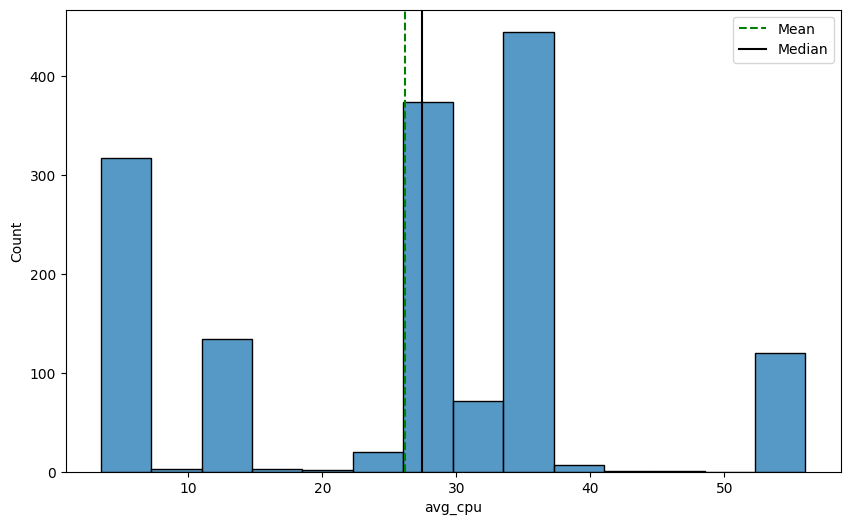

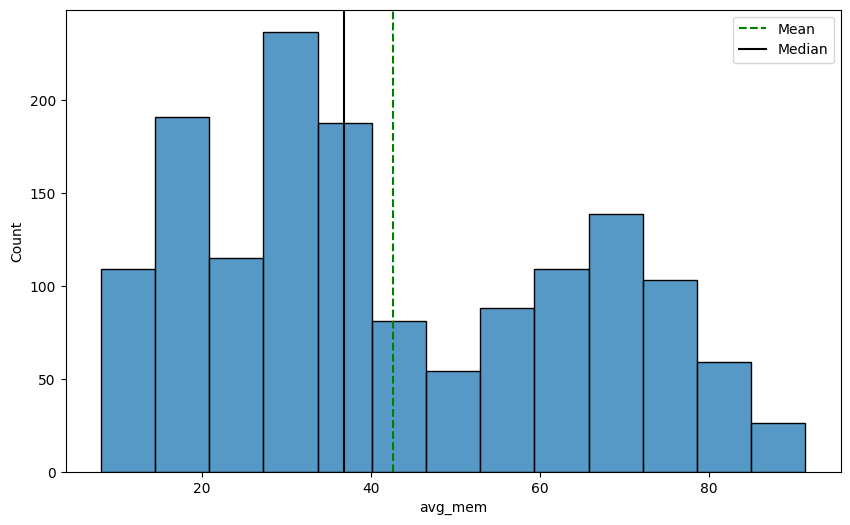

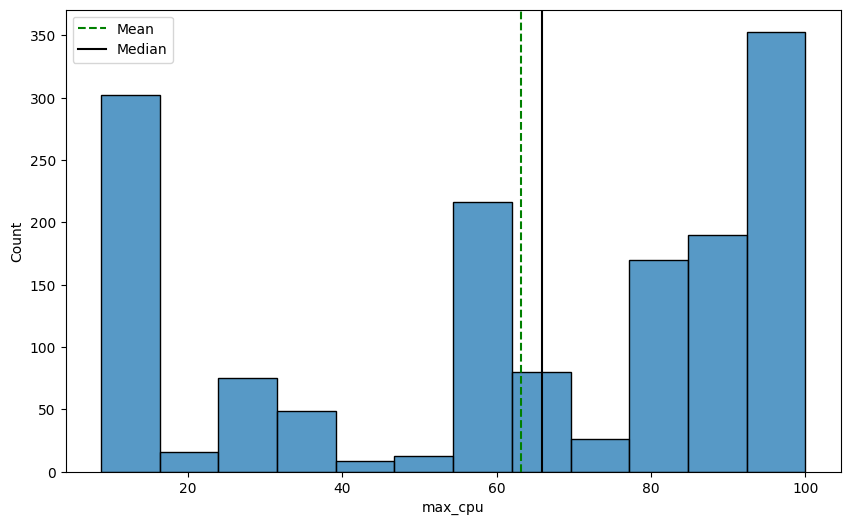

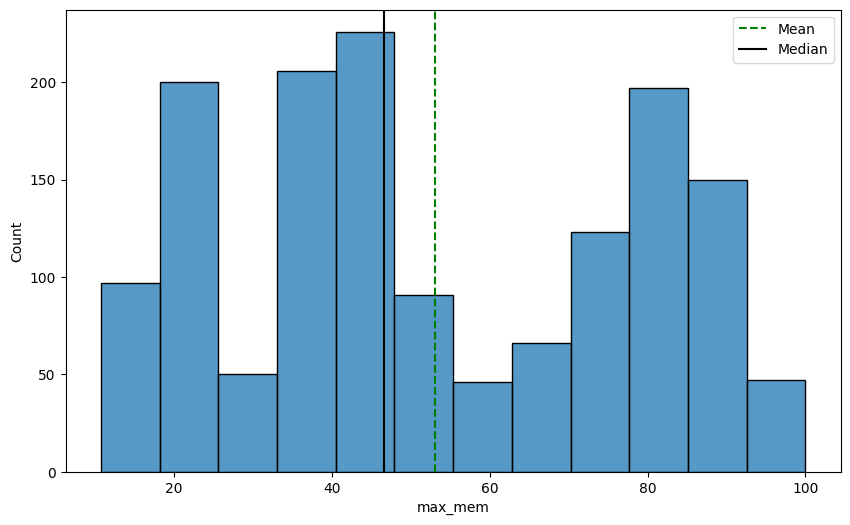

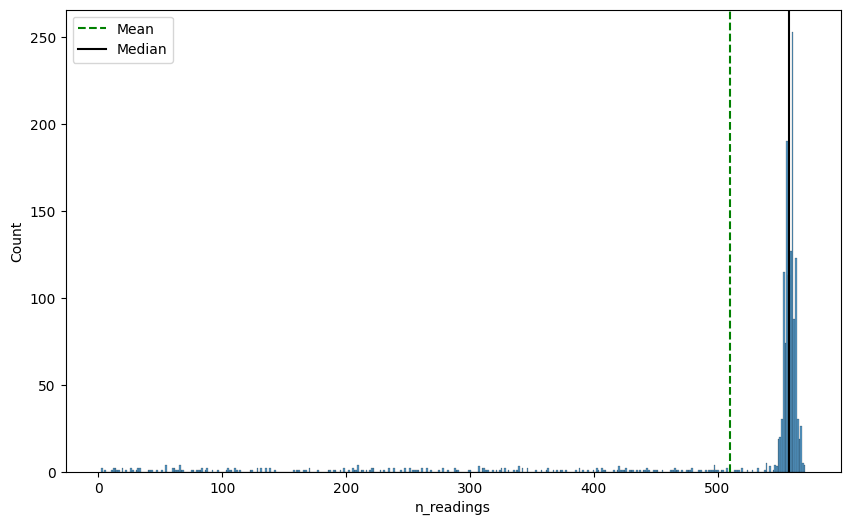

In [67]:
for col in ["avg_cpu", "avg_mem","max_cpu","max_mem","n_readings"]:
    histogram_plot(eda, col)

**Observations**

- Average CPU and memory utilization are distributed across several distinct bands rather than a single peak, suggesting the fleet contains multiple workload archetypes with different resource consumption patterns.

- Average memory utilization is generally higher and more widely spread than CPU utilization, indicating that memory pressure is a more significant constraint for many workloads.

- Peak CPU and peak memory utilization are concentrated near 100%, showing that a substantial portion of VMs experience periods of resource saturation even when their average utilization remains moderate.

- Most VMs have close to the full expected number of telemetry readings (~550+), while a smaller group contains significantly fewer observations, likely due to shorter VM lifetimes or partial monitoring coverage.

### Bivariate analysis

***Prompt***:

<font size=3 color="#4682B4"><b> Compute and visualize correlations between utilization metrics, provisioned resources, and monitoring coverage using a heatmap.
</font>

Correlation heatmap across the engineered numeric summaries.

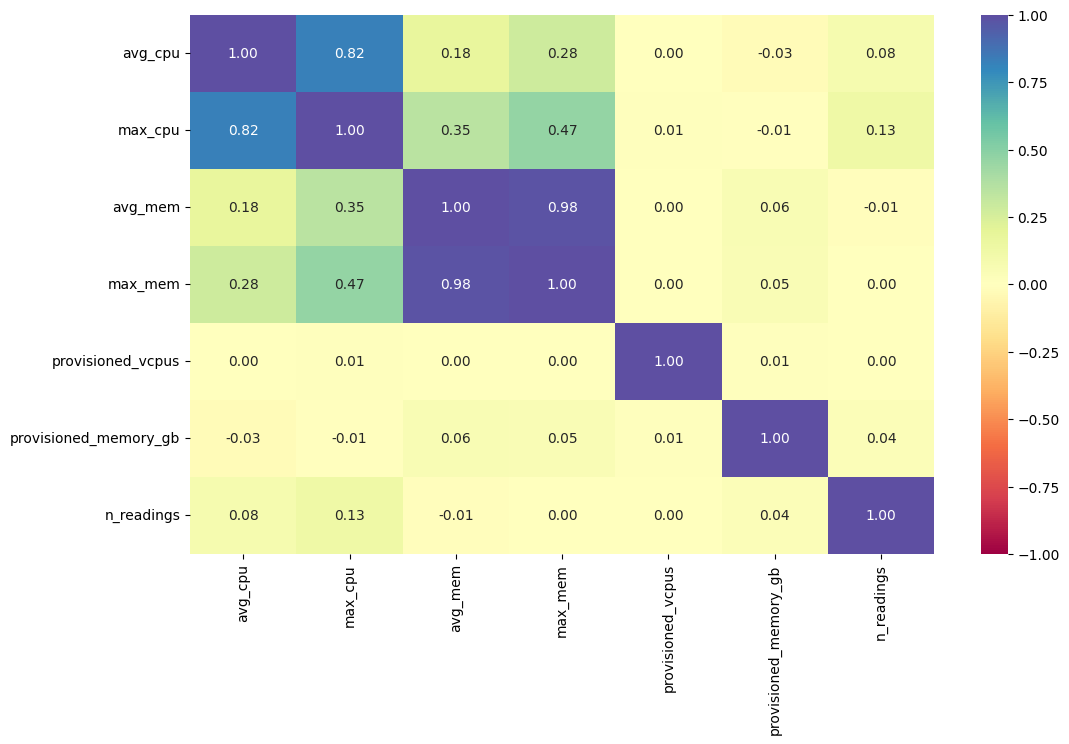

In [68]:
plt.figure(figsize=(12, 7))
sns.heatmap(eda[["avg_cpu", "max_cpu", "avg_mem", "max_mem",
                 "provisioned_vcpus", "provisioned_memory_gb", "n_readings"]].corr(),
            annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

**Observations**

- `avg_mem` and `max_mem` are almost perfectly correlated (0.98) across VMs, indicating that VMs with high average memory utilization also tend to have high peak memory utilization.

- CPU metrics show a weaker relationship (`avg_cpu` vs `max_cpu` = 0.82), indicating that CPU demand is more dynamic and burst-prone than memory demand.

- CPU and memory utilization are only weakly correlated (`avg_cpu` vs `avg_mem` = 0.18), demonstrating that compute-heavy and memory-heavy workloads behave differently and should not be optimized using a single utilization metric.

- Provisioned resources show virtually no correlation with actual utilization, indicating that VM sizing decisions alone are poor predictors of workload behaviour and reinforcing the need for data-driven rightsizing.

### CPU vs Memory Utilization Analysis

***Prompt***:

<font size=3 color="#4682B4"><b>Visualize the relationship between average CPU and memory utilization to identify underutilized VMs and potential memory-constrained workloads.
</font>

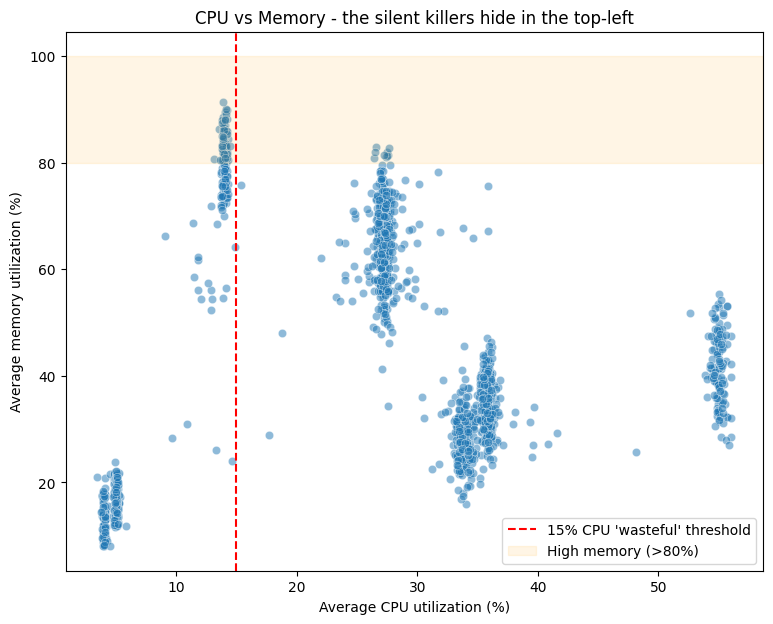

In [69]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=eda, x="avg_cpu", y="avg_mem", alpha=0.5)
plt.axvline(15, color="red", linestyle="--", label="15% CPU 'wasteful' threshold")
plt.axhspan(80, 100, alpha=0.1, color="orange", label="High memory (>80%)")
plt.xlabel("Average CPU utilization (%)")
plt.ylabel("Average memory utilization (%)")
plt.title("CPU vs Memory - the silent killers hide in the top-left")
plt.legend()
plt.show()

**Observations**

- Most low-CPU VMs (<15%) also have low memory utilization, making them strong candidates for rightsizing or further investigation. However, a distinct group of VMs combines low CPU utilization with very high memory utilization (>80%).

- These high-memory, low-CPU workloads would be incorrectly flagged as waste by a CPU-only optimization rule, demonstrating that both CPU and memory utilization must be considered when identifying optimization opportunities.

### Time-of-Day Analysis: Do Some VMs Follow Business-Hour Patterns?

***Prompt***:

<font size=3 color="#4682B4"><b> Engineer business-hours activity features, compute business vs off-hours CPU usage patterns, and identify VMs with strong workday-driven utilization.
</font>

Some workloads are busier during business hours than overnight. Identify them by comparing daytime to nighttime CPU utilization, flagging VMs whose daytime CPU is at least **3×** their nighttime CPU.

In [70]:
# add hour-of-day to every reading
util["hour"] = pd.to_datetime(util["timestamp"], unit="s", utc=True).dt.hour

# average CPU during business hours vs non-business hours, per VM
util["is_business_hours"] = util["hour"].between(9, 17)

business_activity_features = (
    util.groupby(["vm_id", "is_business_hours"])["avg_cpu_5min"]
        .mean()
        .unstack()
)

business_activity_features.columns = ["off_hours_cpu", "business_hours_cpu"]

# business-hours ratio: how much busier is the VM during working hours?
# epsilon avoids divide-by-zero for VMs that are idle outside business hours
business_activity_features["business_hours_ratio"] = (
    business_activity_features["business_hours_cpu"] /
    (business_activity_features["off_hours_cpu"] + 0.5)
)

# keep this feature for downstream clustering
business_activity_features = business_activity_features.reset_index()

# flag VMs that show a strong business-hours usage pattern
business_hours_vm_ids = business_activity_features[
    business_activity_features["business_hours_ratio"] > 3
]["vm_id"]

print(
    "VMs with strong business-hours activity "
    "(business_hours_ratio > 3):",
    len(business_hours_vm_ids)
)

VMs with strong business-hours activity (business_hours_ratio > 3): 547


***Prompt***:

<font size=3 color="#4682B4"><b> Visualize the average hourly CPU utilization pattern of business-hours-driven VMs to identify daytime usage trends.
</font>

Examine the hourly CPU curve for the bursty group to verify activity aligns with the business day.

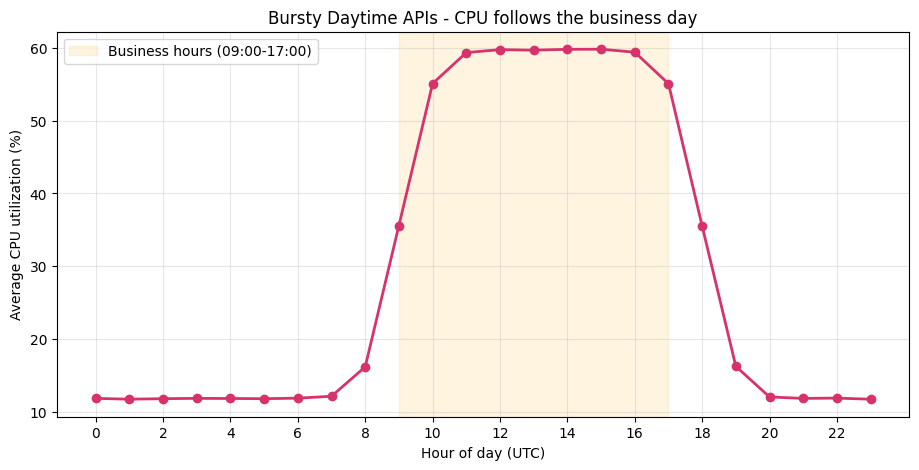

In [71]:
# hourly CPU curve for the bursty group
hourly = util[util["vm_id"].isin(business_hours_vm_ids)].groupby("hour")["avg_cpu_5min"].mean()

plt.figure(figsize=(11, 5))
plt.plot(hourly.index, hourly.values, marker="o", linewidth=2, color="#d6336c")
plt.axvspan(9, 17, alpha=0.12, color="orange", label="Business hours (09:00-17:00)")
plt.xlabel("Hour of day (UTC)")
plt.ylabel("Average CPU utilization (%)")
plt.title("Bursty Daytime APIs - CPU follows the business day")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Observations**

- CPU utilization follows a strong business-hours pattern, rising from ~12% overnight to nearly 60% during working hours before returning to baseline in the evening.

- The sharp and predictable daytime increase highlights that workload timing contains valuable information beyond average utilization alone, making the **`business_hours_ratio`** a useful feature for distinguishing user-driven workloads during clustering.

## Data Preprocessing

### Dropping VMs with too few readings

***Prompt***:

<font size=3 color="#4682B4"><b> Use the IQR method to detect VMs with unusually low numbers of utilization records and assess monitoring coverage outliers
</font>

VMs with substantially fewer readings than the rest of the fleet are flagged as outliers using the IQR rule (`Q1 - 1.5 * IQR`) on the `n_readings` distribution. These short-observation VMs are excluded because their utilization profile is not statistically reliable.

In [72]:
# IQR-based lower bound on readings per VM
readings_per_vm = util.groupby("vm_id").size()

Q1  = readings_per_vm.quantile(0.25)
Q3  = readings_per_vm.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR

print(f"Q1 of n_readings:          {Q1}")
print(f"Q3 of n_readings:          {Q3}")
print(f"IQR:                       {IQR}")
print(f"Lower-bound cutoff:        {lower_bound}")
print(f"VMs below the lower bound: {(readings_per_vm < lower_bound).sum()}")

Q1 of n_readings:          553.0
Q3 of n_readings:          561.0
IQR:                       8.0
Lower-bound cutoff:        541.0
VMs below the lower bound: 252


***Prompt***:

<font size=3 color="#4682B4"><b> Remove VMs with insufficient monitoring data and create cleaned VM metadata and utilization datasets for downstream analysis.
</font>

In [73]:
# drop VMs whose reading count falls below the IQR lower bound
sparse_vms = readings_per_vm[readings_per_vm < lower_bound].index

print("VMs total:         ", readings_per_vm.shape[0])
print("Sparse VMs dropped:", len(sparse_vms))
print("VMs retained:      ", readings_per_vm.shape[0] - len(sparse_vms))

util_clean      = util[~util["vm_id"].isin(sparse_vms)].copy()
vm_master_clean = vm_master[~vm_master["vm_id"].isin(sparse_vms)].copy()

VMs total:          1499
Sparse VMs dropped: 252
VMs retained:       1247


**Observations**

- The IQR lower bound excludes the short-lived VMs whose reading count sits well below the rest of the fleet.
- The retained VMs all have a comparable observation window, so engineered features summarise behaviour on a like-for-like basis.

## Feature Engineering

Transform each VM's time series into a single behavioural fingerprint: one row per VM with a set of engineered features.

**Design note on source columns:** For rightsizing, peak demand matters more than average utilization. Therefore, `p95_*`, `idle_*`, and `peak_*` features are computed from `max_cpu_5min` and `max_memory_5min` to capture worst-case behavior within each monitoring window, while `avg_*` and `std_*` features use the per-window averages to describe typical load and workload stability.


**Behavioural features (used for clustering):**
- **`avg_cpu`** - Mean of per-window average CPU utilization (typical CPU load).
- **`p95_cpu`** - 95th percentile of per-window peak CPU (upper envelope of demand, robust to single extreme spikes).
- **`std_cpu`** - Standard deviation of per-window average CPU (workload stability).
- **`idle_cpu`** - Percentage of windows where even the peak CPU stayed below 5% (windows that were truly inactive throughout).
- **`peak_cpu`** - Percentage of windows where peak CPU exceeded 80% (saturation events).
- **`avg_mem`** - Mean of per-window average memory utilization (typical memory consumption).
- **`p95_mem`** - 95th percentile of per-window peak memory (upper envelope of memory demand).
- **`std_mem`** - Standard deviation of per-window average memory (memory stability).
- **`idle_mem`** - Percentage of windows where even the peak memory stayed below 5%.
- **`peak_mem`** - Percentage of windows where peak memory exceeded 80%.

***Prompt***:

<font size=3 color="#4682B4"><b> Generate per-VM behavioral features capturing average, peak, variability, idle time, and high-utilization patterns for CPU and memory usage.
</font>

In [74]:
# aggregate the 5-minute readings into per-VM behavioural features
cpu_mem_features = util_clean.groupby("vm_id").agg(
    avg_cpu  = ("avg_cpu_5min",    "mean"),
    p95_cpu  = ("max_cpu_5min",    lambda x: np.percentile(x, 95)),
    std_cpu  = ("avg_cpu_5min",    "std"),
    idle_cpu = ("max_cpu_5min",    lambda x: (x < 5).mean() * 100),
    peak_cpu = ("max_cpu_5min",    lambda x: (x > 80).mean() * 100),
    avg_mem  = ("avg_memory_5min", "mean"),
    p95_mem  = ("max_memory_5min", lambda x: np.percentile(x, 95)),
    std_mem  = ("avg_memory_5min", "std"),
    idle_mem = ("max_memory_5min",    lambda x: (x < 5).mean() * 100),
    peak_mem = ("max_memory_5min",    lambda x: (x > 80).mean() * 100),

).reset_index()

cpu_mem_features.head()

,vm_id,avg_cpu,p95_cpu,std_cpu,idle_cpu,peak_cpu,avg_mem,p95_mem,std_mem,idle_mem,peak_mem
0,vm_00000,36.713441,54.3780,6.263248,0.000000,0.000000,37.984649,45.402,1.078886,0.0,0.000000
1,vm_00001,56.013196,91.6960,10.905366,0.000000,22.441652,47.486643,58.692,2.336216,0.0,0.000000
2,vm_00002,14.043124,25.7580,3.892891,0.179533,0.000000,75.836643,80.890,0.864043,0.0,18.850987
3,vm_00004,27.124486,69.3670,19.586019,0.000000,0.720721,60.805441,73.743,3.641546,0.0,0.000000
4,vm_00005,35.706089,53.8025,6.302991,0.000000,0.000000,32.476143,36.384,1.818341,0.0,0.000000


### Adding workload category

In addition to the CPU and memory utilization features derived from telemetry data, we also retain a few VM provisioning and workload characteristics:

- `provisioned_vcpus`
- `provisioned_memory_gb`
- `is_delay_insensitive`

These attributes are included in the master feature table to help interpret and profile the clusters after clustering is performed.

> Note: It is important to note that the workload category itself (`vm_category`) is **not used as an input feature for clustering**. Since clustering is an unsupervised learning technique, we want the algorithm to discover natural groupings based on VM behavior rather than predefined labels. The category information is retained only for post-clustering analysis and cluster interpretation.

***Prompt***:

<font size=3 color="#4682B4"><b> Create a binary feature indicating whether a VM belongs to a delay-insensitive workload category.
</font>

In [75]:
# binary flag for delay-insensitive workloads (useful when describing the clusters)
vm_master_clean["is_delay_insensitive"] = (vm_master_clean["vm_category"] == "Delay-Insensitive").astype(int)

***Prompt***:

<font size=3 color="#4682B4"><b> Combine provisioning details, workload attributes, utilization features, and business-hours activity metrics into a unified feature dataset.
</font>

In [76]:
features = (
    vm_master_clean[["vm_id", "vm_category", "provisioned_vcpus", "provisioned_memory_gb",
                    "is_delay_insensitive"]]
    .merge(cpu_mem_features, on="vm_id", how="inner")
    .merge(business_activity_features[["vm_id", "business_hours_ratio"]], on="vm_id", how="left")
)

# a few VMs (e.g. very short-lived) may lack an overnight reading -> ratio is NaN; fill with 1 (flat)
features["business_hours_ratio"] = features["business_hours_ratio"].fillna(1.0)
features.head()

,vm_id,vm_category,provisioned_vcpus,provisioned_memory_gb,is_delay_insensitive,avg_cpu,p95_cpu,std_cpu,idle_cpu,peak_cpu,avg_mem,p95_mem,std_mem,idle_mem,peak_mem,business_hours_ratio
0,vm_00000,Interactive,8,64,0,36.713441,54.3780,6.263248,0.000000,0.000000,37.984649,45.402,1.078886,0.0,0.000000,1.068040
1,vm_00001,Delay-Insensitive,16,64,1,56.013196,91.6960,10.905366,0.000000,22.441652,47.486643,58.692,2.336216,0.0,0.000000,1.018909
2,vm_00002,Delay-Insensitive,8,8,1,14.043124,25.7580,3.892891,0.179533,0.000000,75.836643,80.890,0.864043,0.0,18.850987,0.961518
3,vm_00004,Interactive,8,4,0,27.124486,69.3670,19.586019,0.000000,0.720721,60.805441,73.743,3.641546,0.0,0.000000,3.352814
4,vm_00005,Interactive,4,32,0,35.706089,53.8025,6.302991,0.000000,0.000000,32.476143,36.384,1.818341,0.0,0.000000,1.064060


### Engineering a Burstiness Feature


Add `burstiness_ratio`, which measures how much higher a VM's P95 CPU utilization is compared to its average CPU utilization. This helps distinguish stable workloads from bursty ones and is used as an input feature for clustering.

To reduce the impact of extreme outliers, the ratio is capped at the 99th percentile so that unusually bursty or nearly idle VMs do not dominate distance calculations.

***Prompt***:

<font size=3 color="#4682B4"><b> Create a CPU burstiness feature from average and peak utilization, cap extreme outliers, and inspect the updated feature set.
</font>

In [77]:
# burstiness: how high the P95 sits above the average (epsilon avoids divide-by-zero)
features["burstiness_ratio"] = features["p95_cpu"] / (features["avg_cpu"] + 0.001)

# cap burstiness at the 99th percentile so extreme spikes do not dominate distances
cap = features["burstiness_ratio"].quantile(0.99)
features["burstiness_ratio"] = features["burstiness_ratio"].clip(upper=cap)
print("Burstiness ratio capped at:", round(cap, 2))

features.head()

Burstiness ratio capped at: 2.95


,vm_id,vm_category,provisioned_vcpus,provisioned_memory_gb,is_delay_insensitive,avg_cpu,p95_cpu,std_cpu,idle_cpu,peak_cpu,avg_mem,p95_mem,std_mem,idle_mem,peak_mem,business_hours_ratio,burstiness_ratio
0,vm_00000,Interactive,8,64,0,36.713441,54.3780,6.263248,0.000000,0.000000,37.984649,45.402,1.078886,0.0,0.000000,1.068040,1.481107
1,vm_00001,Delay-Insensitive,16,64,1,56.013196,91.6960,10.905366,0.000000,22.441652,47.486643,58.692,2.336216,0.0,0.000000,1.018909,1.637014
2,vm_00002,Delay-Insensitive,8,8,1,14.043124,25.7580,3.892891,0.179533,0.000000,75.836643,80.890,0.864043,0.0,18.850987,0.961518,1.834077
3,vm_00004,Interactive,8,4,0,27.124486,69.3670,19.586019,0.000000,0.720721,60.805441,73.743,3.641546,0.0,0.000000,3.352814,2.557263
4,vm_00005,Interactive,4,32,0,35.706089,53.8025,6.302991,0.000000,0.000000,32.476143,36.384,1.818341,0.0,0.000000,1.064060,1.506774


### Scaling

The clustering features focus on VM behaviour rather than provisioning characteristics. Provisioning and categorical attributes are retained for cluster profiling but are not used as clustering inputs.

Before clustering, all features are standardized using `StandardScaler` so that each feature contributes equally to the distance calculations used by K-Means.

***Prompt***:

<font size=3 color="#4682B4"><b> Organize behavioral features into modular groups and select the feature set to be used for clustering.

</font>

In [78]:
# ---- Modular feature definition (behavioural only - no categorical, no provisioning) ----
# Each group is a behavioural dimension. Add or remove groups here to reshape the model.
FEATURE_GROUPS = {
    "cpu":          ["avg_cpu", "p95_cpu", "std_cpu", "idle_cpu", "peak_cpu"],
    "memory":       ["avg_mem", "p95_mem", "std_mem", "idle_mem", "peak_mem"],
    "time_of_day":  ["business_hours_ratio"],
    "burstiness":   ["burstiness_ratio"],
}

# Which groups are active for this run. Drop a key to ablate that dimension.
ACTIVE_FEATURE_GROUPS = ["cpu", "memory", "time_of_day", "burstiness"]

CLUSTERING_FEATURES = [f for g in ACTIVE_FEATURE_GROUPS for f in FEATURE_GROUPS[g]]
print(f"Using {len(CLUSTERING_FEATURES)} behavioural features across {len(ACTIVE_FEATURE_GROUPS)} groups:")
print(CLUSTERING_FEATURES)

Using 12 behavioural features across 4 groups:
['avg_cpu', 'p95_cpu', 'std_cpu', 'idle_cpu', 'peak_cpu', 'avg_mem', 'p95_mem', 'std_mem', 'idle_mem', 'peak_mem', 'business_hours_ratio', 'burstiness_ratio']


***Prompt***:

<font size=3 color="#4682B4"><b>Select the clustering features and standardize them for clustering analysis.
</font>

In [79]:
subset = features[CLUSTERING_FEATURES].copy()

# scaling the data before clustering
scaler        = StandardScaler()
subset_scaled = scaler.fit_transform(subset)

***Prompt***:

<font size=3 color="#4682B4"><b> Create a DataFrame of the standardized features and verify the scaling results using summary statistics.

</font>

In [80]:
# creating a dataframe of the scaled data
subset_scaled_df = pd.DataFrame(subset_scaled, columns=subset.columns)
subset_scaled_df.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
avg_cpu,0.0,1.0,-1.56,2.07
p95_cpu,-0.0,1.0,-1.60,1.54
std_cpu,0.0,1.0,-1.13,1.84
idle_cpu,0.0,1.0,-0.51,3.78
peak_cpu,-0.0,1.0,-0.54,3.31
avg_mem,-0.0,1.0,-1.57,2.23
p95_mem,-0.0,1.0,-1.65,2.03
std_mem,-0.0,1.0,-1.42,5.69
idle_mem,0.0,0.0,0.00,0.00
peak_mem,0.0,1.0,-0.38,3.59


## Dimensionality Reduction and Visualization using t-SNE

Use t-SNE to project the standardized feature space into 2D and 3D, allowing us to visually explore whether the VMs naturally form distinct groups.

The **perplexity** parameter controls how t-SNE balances local and global structure. We evaluate multiple perplexity values to verify that the observed cluster patterns are stable and not an artefact of a particular setting.

### 2D t-SNE across multiple perplexities (50, 100, 150)

***Prompt***:

<font size=3 color="#4682B4"><b> Generate 2D t-SNE projections using multiple perplexity values and compare the resulting embeddings.

</font>

In [81]:
# run 2D t-SNE at three perplexities and store each projection
PERPLEXITIES = [50, 100, 150]
tsne_2d_results = {}

for p in PERPLEXITIES:
    tsne_model = TSNE(n_components=2, random_state=RS, perplexity=p, init="pca")
    proj = tsne_model.fit_transform(subset_scaled)
    tsne_2d_results[p] = pd.DataFrame(proj, columns=["Feature 1", "Feature 2"])
    print(f"perplexity={p}: KL divergence = {tsne_model.kl_divergence_:.4f}")

perplexity=50: KL divergence = 0.2952
perplexity=100: KL divergence = 0.1432
perplexity=150: KL divergence = 0.0802


***Prompt***:

<font size=3 color="#4682B4"><b> Visualize and compare the 2D t-SNE embeddings across different perplexity values to assess clustering structure stability.
</font>

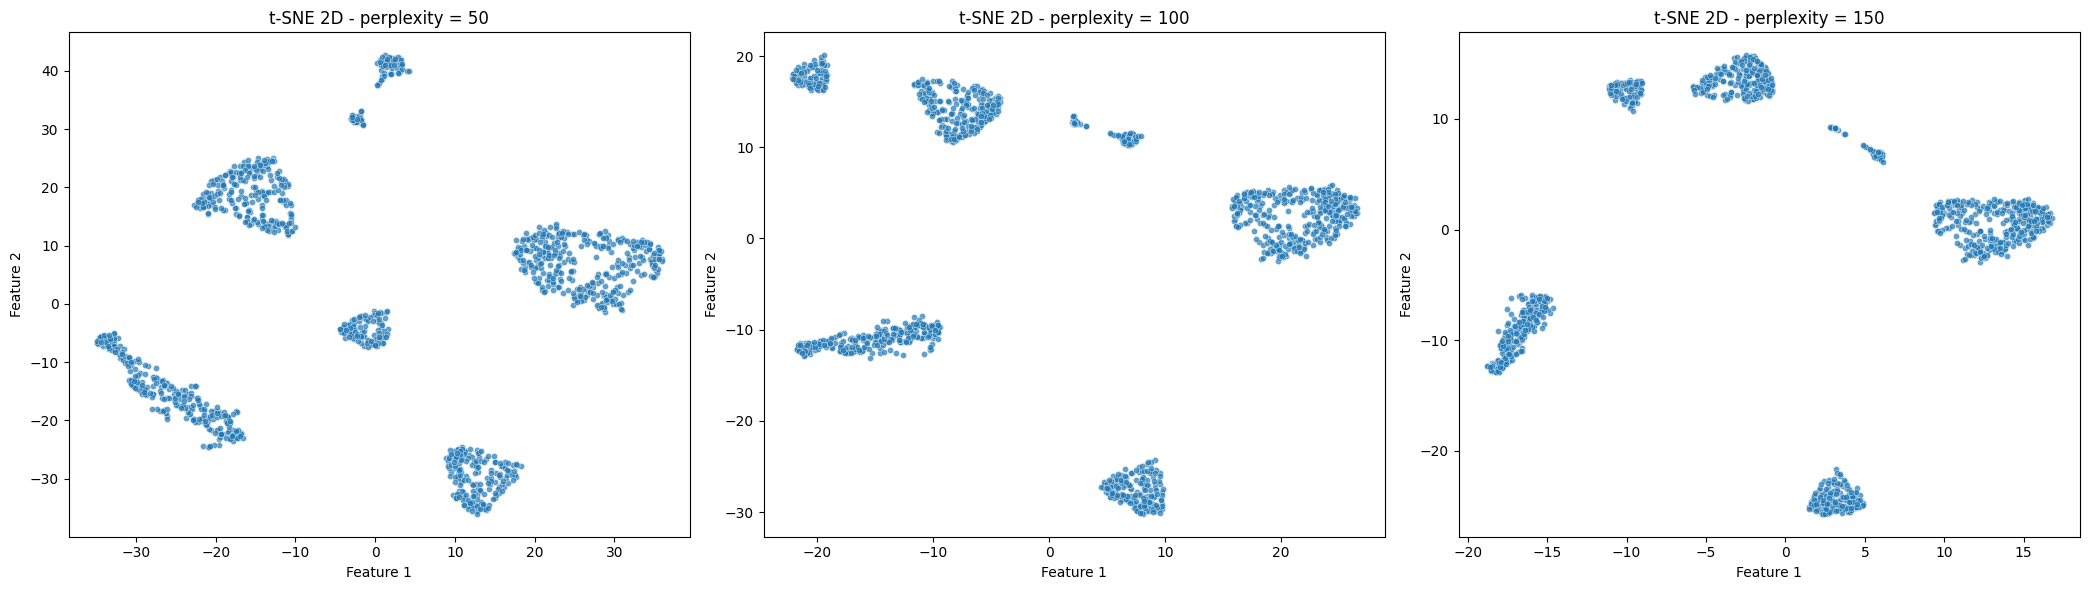

In [82]:
# side-by-side scatter plots of the three 2D projections
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
for ax, p in zip(axes, PERPLEXITIES):
    sns.scatterplot(data=tsne_2d_results[p], x="Feature 1", y="Feature 2",
                    ax=ax, alpha=0.7, s=20)
    ax.set_title(f"t-SNE 2D - perplexity = {p}")
plt.tight_layout()
plt.show()

**Observations**

- Similar cluster patterns appear across all three perplexity values, indicating that the underlying structure is stable and not highly sensitive to the t-SNE configuration.

- Several well-separated groups are consistently visible, suggesting that the engineered features capture meaningful differences in VM behaviour.

- As perplexity increases from 50 to 150, the clusters become more compact and visually cleaner, while preserving the overall cluster arrangement.

- We use the **perplexity = 100** projection for subsequent visualizations, as it provides a good balance between local detail and overall cluster structure.

### 3D t-SNE

A 3D projection is useful when groups overlap in 2D - a third axis can reveal separation that a 2D plot hides.

***Prompt***:

<font size=3 color="#4682B4"><b> Generate a 3D t-SNE embedding using the selected perplexity and inspect the resulting projection.
</font>

In [83]:
# 3D t-SNE at the chosen perplexity
tsne_3d_model = TSNE(n_components=3, random_state=RS, perplexity=100, init="pca")
tsne_3d_proj  = tsne_3d_model.fit_transform(subset_scaled)

tsne_3d_data = pd.DataFrame(tsne_3d_proj, columns=["Feature 1", "Feature 2", "Feature 3"])
print(f"3D t-SNE KL divergence: {tsne_3d_model.kl_divergence_:.4f}")
tsne_3d_data.head()

3D t-SNE KL divergence: 0.1000


,Feature 1,Feature 2,Feature 3
0,1.818185,1.537868,-7.200449
1,-4.973711,-4.729240,-9.055260
2,0.773633,5.296645,-3.732691
3,5.454873,2.517622,6.077074
4,-0.673601,2.482010,-9.736185


***Prompt***:

<font size=3 color="#4682B4"><b> Create an interactive 3D visualization of the t-SNE embedding to explore cluster separation across all dimensions.
</font>

In [84]:
# interactive 3D scatter - rotate to inspect group separation along all three axes
fig = px.scatter_3d(
    tsne_3d_data,
    x="Feature 1", y="Feature 2", z="Feature 3",
    opacity=0.7,
    title="t-SNE 3D projection (perplexity = 100)",
)
fig.update_traces(marker=dict(size=3))
fig.update_layout(height=650)
fig.show()

**Observations**

- The 3D projection confirms the presence of multiple distinct VM groupings, with separations visible along all three t-SNE axes.
- Several clusters that visually overlap in the 2D plot become clearly separated in 3D, supporting the choice of K-Means with a moderate number of clusters in the next step.

## Model Building: K-Means Clustering

***Prompt***:

<font size=3 color="#4682B4"><b> Create a copy of the scaled feature dataset for K-Means clustering.
</font>

In [85]:
k_means_df = subset_scaled_df.copy()

**Elbow Method to find a candidate number of clusters.**

***Prompt***:

<font size=3 color="#4682B4"><b> Fit K-Means models for cluster counts ranging from 2 to 10 and compute WCSS for each configuration.
</font>

In [86]:
clusters = range(2, 11)
WCSS = []

for k in clusters:
    model = KMeans(n_clusters=k, random_state=RS, n_init=10)
    model.fit(subset_scaled_df)
    wcss = model.inertia_
    WCSS.append(wcss)
    print("Number of Clusters:", k, "\twcss:", round(wcss, 1))

Number of Clusters: 2 	wcss: 8527.7
Number of Clusters: 3 	wcss: 5784.5
Number of Clusters: 4 	wcss: 3721.6
Number of Clusters: 5 	wcss: 2416.9
Number of Clusters: 6 	wcss: 1840.8
Number of Clusters: 7 	wcss: 1506.6
Number of Clusters: 8 	wcss: 1242.1
Number of Clusters: 9 	wcss: 1078.0
Number of Clusters: 10 	wcss: 925.8


***Prompt***:

<font size=3 color="#4682B4"><b> Visualize the WCSS values across cluster counts (2–10) using the Elbow Method to identify the optimal number of clusters.
</font>

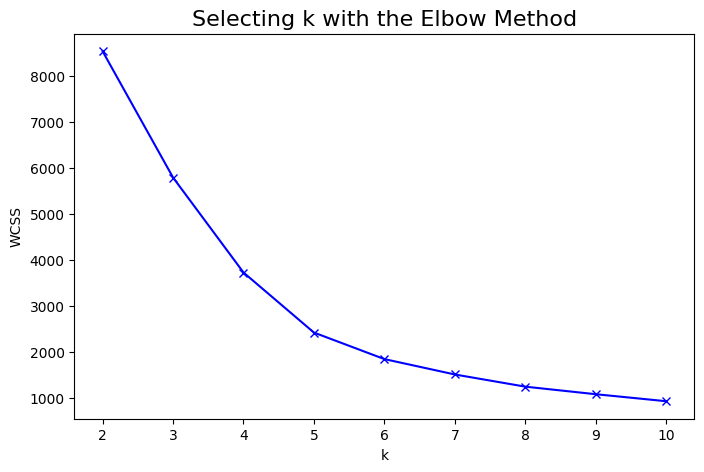

In [87]:
plt.figure(figsize=(8, 5))
plt.plot(clusters, WCSS, "bx-")
plt.xlabel("k")
plt.ylabel("WCSS")
plt.title("Selecting k with the Elbow Method", fontsize=16)
plt.show()

**Observations**

- WCSS decreases sharply as the number of clusters increases from 2 to around 6, indicating that each additional cluster captures meaningful structure in the data.
- Beyond **k = 6**, the improvement in WCSS becomes more gradual, suggesting diminishing returns. The candidate range is **k = 5–7**, which is now evaluated with silhouette scores.

**Silhouette scores.**

***Prompt***:

<font size=3 color="#4682B4"><b> Evaluate K-Means models with 2–9 clusters using silhouette scores to identify the optimal cluster count.
</font>

In [88]:
sil_score = []
cluster_list = range(2, 10)
for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters, random_state=RS, n_init=10)
    preds = clusterer.fit_predict(subset_scaled_df)
    score = silhouette_score(k_means_df, preds)
    sil_score.append(score)
    print("For n_clusters = {}, the silhouette score is {:.4f}".format(n_clusters, score))

For n_clusters = 2, the silhouette score is 0.3865
For n_clusters = 3, the silhouette score is 0.4711
For n_clusters = 4, the silhouette score is 0.5575
For n_clusters = 5, the silhouette score is 0.6157
For n_clusters = 6, the silhouette score is 0.6239
For n_clusters = 7, the silhouette score is 0.6037
For n_clusters = 8, the silhouette score is 0.6303
For n_clusters = 9, the silhouette score is 0.6122


***Prompt***:

<font size=3 color="#4682B4"><b> Visualize silhouette scores across cluster counts (2–9) to identify the optimal number of clusters.
</font>

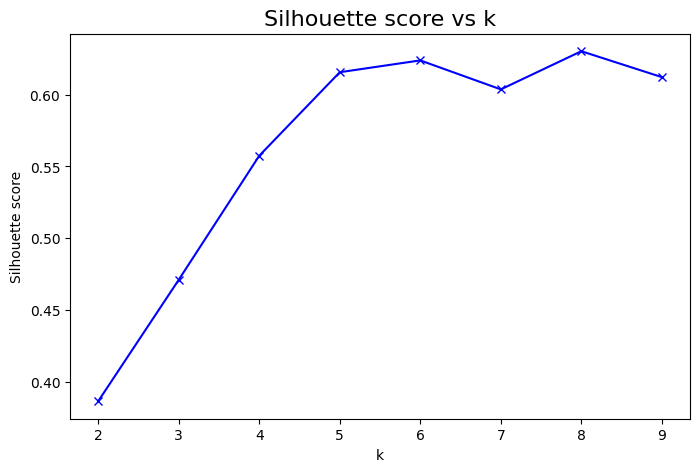

In [89]:
plt.figure(figsize=(8, 5))
plt.plot(cluster_list, sil_score, "bx-")
plt.xlabel("k")
plt.ylabel("Silhouette score")
plt.title("Silhouette score vs k", fontsize=16)
plt.show()

**Observations**

- The silhouette score improves substantially up to **k = 6**, indicating increasingly well-separated and cohesive clusters.

- Although slightly higher scores are observed for larger values of *k*, combining the silhouette results with the elbow analysis supports **k = 6** as the final choice, providing strong cluster quality with good interpretability.

***Prompt***:

<font size=3 color="#4682B4"><b> Train the final K-Means model using 6 clusters on the scaled feature dataset.
</font>

In [90]:
kmeans = KMeans(n_clusters=6, random_state=RS, n_init=10)
kmeans.fit(k_means_df)

KMeans(n_clusters=6, n_init=10, random_state=0)

***Prompt***:

<font size=3 color="#4682B4"><b> Assign the final K-Means cluster labels to the feature dataset and t-SNE projections for downstream analysis and visualization.
</font>

In [91]:
# pick the 2D t-SNE projection used for the final visualization
tsne_2d_data = tsne_2d_results[100].copy()

# adding kmeans cluster labels to the data
k_means_df["KM_segment"]   = kmeans.labels_
features["KM_segment"]     = kmeans.labels_
tsne_2d_data["KM_segment"] = kmeans.labels_
tsne_3d_data["KM_segment"] = kmeans.labels_

## Cluster Profiling

### Visualizing Final Clusters

***Prompt***:

<font size=3 color="#4682B4"><b>Visualize the final K-Means segments on the 2D t-SNE projection to assess cluster separation and structure.
</font>

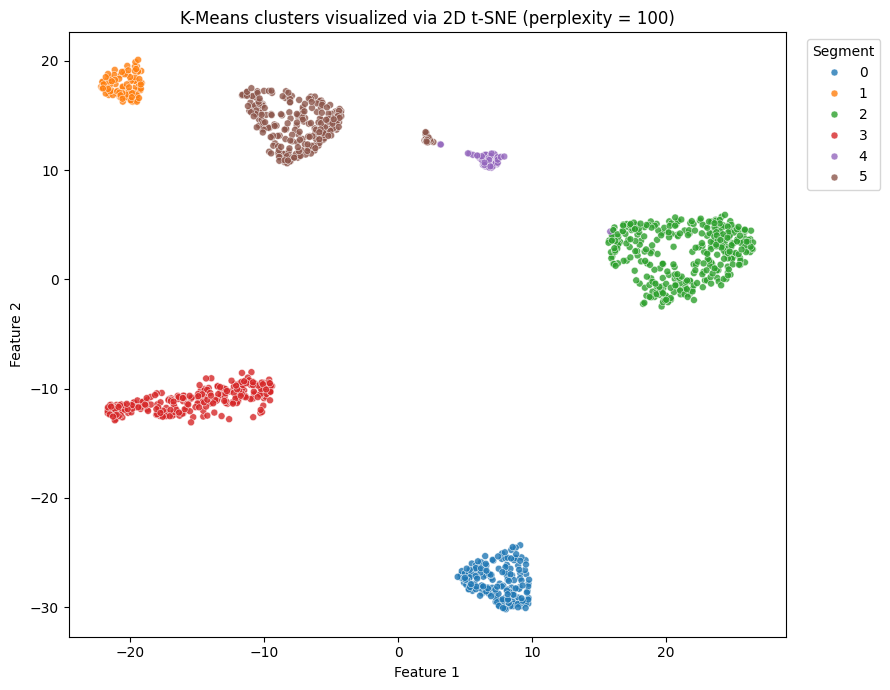

In [92]:
# visualizing the final clusters using the 2D t-SNE projection (perplexity=100)
plt.figure(figsize=(9, 7))
sns.scatterplot(data=tsne_2d_data, x="Feature 1", y="Feature 2",
                hue="KM_segment", palette="tab10", s=25, alpha=0.8)
plt.title("K-Means clusters visualized via 2D t-SNE (perplexity = 100)")
plt.legend(title="Segment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

***Prompt***:

<font size=3 color="#4682B4"><b> Create an interactive 3D visualization of the final K-Means clusters using the t-SNE embedding to examine cluster separation.
</font>

In [93]:
# interactive 3D view of the final clusters
fig = px.scatter_3d(
    tsne_3d_data, x="Feature 1", y="Feature 2", z="Feature 3",
    color=tsne_3d_data["KM_segment"].astype(str),
    opacity=0.75,
    title="K-Means clusters visualized via 3D t-SNE",
    labels={"color": "Segment"},
)
fig.update_traces(marker=dict(size=3))
fig.update_layout(height=650)
fig.show()

**Observations**

- The clusters are generally well separated in both the 2D and 3D t-SNE projections, indicating that K-Means has identified distinct groups of VMs based on their behavioral characteristics.
- A few clusters lie close to one another but remain distinguishable along the third axis in 3D, confirming that the feature set captures meaningful behavioural differences.

### Profiling the Clusters

Cluster labels are numeric and carry no business meaning. Compute the average value of each feature within every cluster - both the clustering features and the provisioning/lifecycle context - to identify the defining characteristics of each group.

***Prompt***:

<font size=3 color="#4682B4"><b> Profile each K-Means cluster by summarizing behavioral, provisioning, and workload characteristics, and compare segment sizes.
</font>

In [94]:
# columns used to profile the clusters: clustering features + provisioning + lifetime + delay flag
PROFILING_COLS = CLUSTERING_FEATURES + [
    "provisioned_vcpus", "provisioned_memory_gb",
   "is_delay_insensitive",
]

km_cluster_profile = features.groupby("KM_segment")[PROFILING_COLS].mean()
km_cluster_profile["count_in_each_segment"] = (features.groupby("KM_segment")["vm_id"].count().values)
km_cluster_profile.style.highlight_max(color="lightgreen", axis=0)

,avg_cpu,p95_cpu,std_cpu,idle_cpu,peak_cpu,avg_mem,p95_mem,std_mem,idle_mem,peak_mem,business_hours_ratio,burstiness_ratio,provisioned_vcpus,provisioned_memory_gb,is_delay_insensitive,count_in_each_segment
KM_segment,,,,,,,,,,,,,,,,
0,33.827781,93.746508,29.483116,0.657808,19.308261,28.311115,35.873870,2.430941,0.000000,0.000000,4.642945,2.770547,12.369565,23.695652,0.000000,184
1,55.017329,83.879034,10.964516,0.000000,10.995860,41.705963,55.018500,3.750316,0.000000,0.000000,0.992010,1.524594,11.711538,25.461538,1.000000,104
2,27.212974,70.021593,19.979803,0.824278,0.788250,65.202415,77.678000,3.616246,0.000000,16.067952,3.288259,2.573282,12.321839,26.701149,0.000000,348
3,4.769982,10.029898,2.335083,34.232725,0.000000,16.005582,18.965126,0.855436,0.000000,0.000000,0.903668,2.098331,11.896296,25.762963,0.240741,270
4,14.192188,26.165821,4.231359,0.082789,0.005293,83.209835,87.191269,1.120164,0.000000,92.912737,1.001665,1.834449,10.358209,28.000000,0.985075,67
5,33.310744,48.507423,5.827019,0.013711,0.000000,39.398720,45.452735,1.579804,0.000000,0.320624,1.025299,1.479038,12.729927,24.248175,0.113139,274


**How to read this table:** Each row represents a cluster. The green-highlighted cells indicate the highest value for a given feature across all clusters. These highlights reveal the behavioural signature of each cluster - which workloads are CPU-intensive, memory-intensive, bursty, idle, or otherwise distinct from the rest of the fleet.

### Assigning Business-Friendly Cluster Labels

#### Cluster: 0

In [95]:
km_cluster_profile.iloc[0]

avg_cpu                   33.827781
p95_cpu                   93.746508
std_cpu                   29.483116
idle_cpu                   0.657808
peak_cpu                  19.308261
avg_mem                   28.311115
p95_mem                   35.873870
std_mem                    2.430941
idle_mem                   0.000000
peak_mem                   0.000000
business_hours_ratio       4.642945
burstiness_ratio           2.770547
provisioned_vcpus         12.369565
provisioned_memory_gb     23.695652
is_delay_insensitive       0.000000
count_in_each_segment    184.000000
Name: 0, dtype: float64

**Observations**
- CPU utilization is highly variable (`avg_cpu` 33.8%, `p95_cpu` 93.7%, `std_cpu` 29.5%), indicating frequent demand spikes.
- Memory utilization remains low and stable (`avg_mem` 28.3%), suggesting the workload is primarily compute-driven.
- The highest `business_hours_ratio` in the fleet (4.64) indicates activity is strongly concentrated during working hours.
- High burstiness (`burstiness_ratio` 2.73) and 100% Interactive classification suggest demand is driven by user activity.

**Profile:** Business-Hours Bursty Workloads

**Recommended Action:** Implement schedule-aware horizontal autoscaling.

#### Cluster: 1

In [96]:
km_cluster_profile.iloc[1]

avg_cpu                   55.017329
p95_cpu                   83.879034
std_cpu                   10.964516
idle_cpu                   0.000000
peak_cpu                  10.995860
avg_mem                   41.705963
p95_mem                   55.018500
std_mem                    3.750316
idle_mem                   0.000000
peak_mem                   0.000000
business_hours_ratio       0.992010
burstiness_ratio           1.524594
provisioned_vcpus         11.711538
provisioned_memory_gb     25.461538
is_delay_insensitive       1.000000
count_in_each_segment    104.000000
Name: 1, dtype: float64

**Observations**
- CPU utilization is consistently high (`avg_cpu` 55.0%, `p95_cpu` 83.9%) with relatively low variability.
- No idle periods are observed (`idle_cpu` 0%), and activity remains constant throughout the day (`business_hours_ratio` 0.99).
- All VMs are classified as Delay-Insensitive, aligning with a batch-processing workload profile.
- The lowest burstiness in the fleet (`burstiness_ratio` 1.51) makes this the most predictable workload group.

**Profile:** Always-On Batch Workloads

**Recommended Action:** Evaluate spot or preemptible instance migration.

#### Cluster: 2

In [97]:
km_cluster_profile.iloc[2]

avg_cpu                   27.212974
p95_cpu                   70.021593
std_cpu                   19.979803
idle_cpu                   0.824278
peak_cpu                   0.788250
avg_mem                   65.202415
p95_mem                   77.678000
std_mem                    3.616246
idle_mem                   0.000000
peak_mem                  16.067952
business_hours_ratio       3.288259
burstiness_ratio           2.573282
provisioned_vcpus         12.321839
provisioned_memory_gb     26.701149
is_delay_insensitive       0.000000
count_in_each_segment    348.000000
Name: 2, dtype: float64

**Observations**
- Memory utilization is persistently high (`avg_mem` 65.2%, `p95_mem` 77.7%), making memory the dominant resource constraint.
- CPU utilization is moderate (`avg_cpu` 27.2%) and rarely reaches saturation despite periodic bursts.
- Almost no idle CPU or memory time is observed, indicating continuously active workloads.
- A meaningful business-hours effect (`business_hours_ratio` 3.29) suggests user-driven demand layered on top of a large in-memory footprint.

**Profile:** Memory-Intensive Application Workloads

**Recommended Action:** Migrate to memory-optimized VM types.

#### Cluster: 3

In [98]:
km_cluster_profile.iloc[3]

avg_cpu                    4.769982
p95_cpu                   10.029898
std_cpu                    2.335083
idle_cpu                  34.232725
peak_cpu                   0.000000
avg_mem                   16.005582
p95_mem                   18.965126
std_mem                    0.855436
idle_mem                   0.000000
peak_mem                   0.000000
business_hours_ratio       0.903668
burstiness_ratio           2.098331
provisioned_vcpus         11.896296
provisioned_memory_gb     25.762963
is_delay_insensitive       0.240741
count_in_each_segment    270.000000
Name: 3, dtype: float64

**Observations**
- CPU utilization is extremely low (`avg_cpu` 4.77%, `p95_cpu` 10.03%) with the highest idle fraction in the fleet.
- Memory utilization is also minimal (`avg_mem` 16.0%) despite substantial provisioned resources.
- Activity does not follow a business-hours pattern (`business_hours_ratio` 0.90), suggesting lightweight background processes rather than user-facing workloads.
- The cluster contains a mix of Interactive and Delay-Insensitive workloads, indicating a combination of development, standby, and potentially abandoned systems.

**Profile:** Idle / Zombie VMs

**Recommended Action:** Audit ownership and decommission unused resources.

#### Cluster: 4

In [99]:
km_cluster_profile.iloc[4]

avg_cpu                  14.192188
p95_cpu                  26.165821
std_cpu                   4.231359
idle_cpu                  0.082789
peak_cpu                  0.005293
avg_mem                  83.209835
p95_mem                  87.191269
std_mem                   1.120164
idle_mem                  0.000000
peak_mem                 92.912737
business_hours_ratio      1.001665
burstiness_ratio          1.834449
provisioned_vcpus        10.358209
provisioned_memory_gb    28.000000
is_delay_insensitive      0.985075
count_in_each_segment    67.000000
Name: 4, dtype: float64

**Observations**
- Memory utilization is consistently near capacity (`avg_mem` 83.2%, `p95_mem` 87.2%) with very little variation.
- Nearly all readings occur close to the memory ceiling (`peak_mem` 92.9%), leaving limited operational headroom.
- CPU utilization remains low (`avg_cpu` 14.2%), indicating these workloads are constrained by memory rather than compute.
- Workload activity is effectively flat throughout the day (`business_hours_ratio` 1.00), consistent with always-on data services.

**Profile:** Memory-Saturated Workloads

**Recommended Action:** Increase memory capacity or redesign workload memory usage.

#### Cluster: 5

In [100]:
km_cluster_profile.iloc[5]

avg_cpu                   33.310744
p95_cpu                   48.507423
std_cpu                    5.827019
idle_cpu                   0.013711
peak_cpu                   0.000000
avg_mem                   39.398720
p95_mem                   45.452735
std_mem                    1.579804
idle_mem                   0.000000
peak_mem                   0.320624
business_hours_ratio       1.025299
burstiness_ratio           1.479038
provisioned_vcpus         12.729927
provisioned_memory_gb     24.248175
is_delay_insensitive       0.113139
count_in_each_segment    274.000000
Name: 5, dtype: float64

**Observations**
- CPU and memory utilization are both moderate and highly stable (`avg_cpu` 33.3%, `avg_mem` 39.4%).
- The gap between average and peak utilization is small, indicating predictable workload behaviour with minimal spikes.
- Activity remains consistent throughout the day (`business_hours_ratio` 1.03), suggesting background or infrastructure services.
- Low burstiness (`burstiness_ratio` 1.45) and healthy resource utilization indicate a well-balanced workload profile.

**Profile:** Steady-State Production Workloads

**Recommended Action:** Evaluate reserved instances or committed-use discounts.

## Business Insights and Recommendations

- **Adopt archetype-based optimization policies instead of per-VM reviews.** Moving to archetype-based policy means Atlas sets one approved action per group at the leadership level, and applies it consistently across every VM in that group. This is a governance change as much as a technical one: it takes the optimization decision out of individual teams and puts it where it belongs - at the organizational level.

- **Target immediate optimization opportunities through Idle / Zombie VMs and Memory-Saturated Workloads.** Two groups should be addressed first, in parallel.
    - Idle / Zombie VMs - fastest savings: This group consumes fully billable compute while contributing almost nothing. Atlas should establish an organizational policy: any VM in this group that cannot be associated with an active, approved workload within one billing cycle is decommissioned. The burden of proof should sit with the organization to justify continued spend, not with FinOps to justify removal.
    - Memory-Saturated Workloads - highest operational risk: This group is running at 83% memory on average, with frequent spikes above 90%. Atlas is one traffic spike away from a production failure in this segment. Upgrading these to larger configurations is a cost increase, but it is a deliberate risk-management decision — the kind that should be documented and approved at the CFO level rather than deferred.

- **Expand the analysis before production deployment.** While the 2-day, 1500-VM prototype successfully demonstrates that meaningful workload archetypes emerge from behavioural data, a production rollout should use at least 30 days of telemetry across the full fleet and incorporate additional signals such as disk I/O and network throughput to capture longer-term workload patterns and resource bottlenecks.

- **Use behavioural patterns to align infrastructure strategy with workload needs.** Atlas should set these as standing policies rather than renegotiating workload by workload: move steady-state production VMs to 1- or 3-year committed contracts for an immediate 30-60% cost reduction; schedule business-hours bursty VMs to expand before the workday and contract after, eliminating overnight idle spend; migrate memory-intensive VMs to memory-optimized configurations which are a better fit and often cost-neutral; and require a documented compliance review before moving any batch workload to interruptible capacity, given that many of those jobs support regulatory filings that cannot safely be interrupted mid-run.

<font size=6 color='blue'>**Power Ahead!**</font>
___